In [1]:
import pandas as pd 
hotels = pd.read_csv("/kaggle/input/hoteltheme/hotels.csv") 
reviews = pd.read_csv("/kaggle/input/hoteltheme/reviews.csv") 
users = pd.read_csv("/kaggle/input/hoteltheme/users.csv")

In [2]:
# Check missing values in each dataset
print(hotels.isnull().sum())
print(reviews.isnull().sum())
print(users.isnull().sum())

hotel_id                0
hotel_name              0
city                    0
country                 0
star_rating             0
lat                     0
lon                     0
cleanliness_base        0
comfort_base            0
facilities_base         0
location_base           0
staff_base              0
value_for_money_base    0
dtype: int64
review_id                0
user_id                  0
hotel_id                 0
review_date              0
score_overall            0
score_cleanliness        0
score_comfort            0
score_facilities         0
score_location           0
score_staff              0
score_value_for_money    0
review_text              0
dtype: int64
user_id           0
user_gender       0
country           0
age_group         0
traveller_type    0
join_date         0
dtype: int64


In [3]:
# remove duplicates
hotels.drop_duplicates(inplace=True)
reviews.drop_duplicates(inplace=True)
users.drop_duplicates(inplace=True)

In [4]:
# merge reviews with hotels using hotel id
merged_df = reviews.merge(hotels, on='hotel_id', how='left')

# merge the result with users using user id
merged_df = merged_df.merge(users, on='user_id', how='left')

merged_df.head()

,review_id,user_id,hotel_id,review_date,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,...,comfort_base,facilities_base,location_base,staff_base,value_for_money_base,user_gender,country_y,age_group,traveller_type,join_date
0,1,1600,1,2022-10-07,8.7,8.6,8.7,8.5,9.0,8.8,...,8.8,8.9,9.5,8.6,8.0,Female,New Zealand,25-34,Solo,2021-03-21
1,2,432,4,2020-03-24,9.1,10.0,9.1,9.0,8.6,9.4,...,9.0,9.3,8.5,9.5,8.2,Female,United Kingdom,35-44,Couple,2025-04-01
2,3,186,18,2023-12-18,8.8,9.7,8.8,8.3,8.7,8.1,...,8.7,8.6,9.1,8.7,8.4,Female,Spain,55+,Couple,2021-10-28
3,4,1403,19,2022-06-22,8.9,9.0,8.8,8.5,9.6,9.1,...,9.1,8.9,9.7,9.0,8.8,Female,United Kingdom,35-44,Business,2023-10-10
4,5,1723,17,2022-07-02,9.1,8.9,9.5,9.3,8.3,9.4,...,9.3,9.0,9.0,9.1,8.6,Male,Australia,45-54,Family,2023-02-28


In [5]:
merged_df.shape #50000

(50000, 29)

In [6]:
import os
os.makedirs("/kaggle/working/data", exist_ok=True)
merged_df.to_csv("/kaggle/working/data/merged_hotel_data.csv", index=False)

# NEW COUNTRY_GROUP COLUMN

In [7]:
merged_df['country_y'].unique()

array(['New Zealand', 'United Kingdom', 'Spain', 'Australia',
       'United States', 'China', 'United Arab Emirates', 'Canada',
       'Brazil', 'Argentina', 'Germany', 'Netherlands', 'Russia',
       'South Korea', 'Japan', 'Italy', 'India', 'South Africa',
       'Nigeria', 'Thailand', 'Turkey', 'France', 'Singapore', 'Mexico',
       'Egypt'], dtype=object)

In [8]:
# new country groups column
country_map = {
    'United States': 'North_America',
    'Canada': 'North_America',
    'Germany': 'Western_Europe',
    'France': 'Western_Europe',
    'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe',
    'Spain': 'Western_Europe',
    'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia',
    'Japan': 'East_Asia',
    'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia',
    'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East',
    'Turkey': 'Middle_East',
    'Egypt': 'Africa',
    'Nigeria': 'Africa',
    'South Africa': 'Africa',
    'Australia': 'Oceania',
    'New Zealand': 'Oceania',
    'Brazil': 'South_America',
    'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

# Create the country_group column
merged_df['country_group'] = merged_df['country_y'].map(country_map)

# Check the new column
merged_df[['country_y', 'country_group']].head()

,country_y,country_group
0,New Zealand,Oceania
1,United Kingdom,Western_Europe
2,Spain,Western_Europe
3,United Kingdom,Western_Europe
4,Australia,Oceania


In [9]:
merged_df.head()

,review_id,user_id,hotel_id,review_date,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,...,facilities_base,location_base,staff_base,value_for_money_base,user_gender,country_y,age_group,traveller_type,join_date,country_group
0,1,1600,1,2022-10-07,8.7,8.6,8.7,8.5,9.0,8.8,...,8.9,9.5,8.6,8.0,Female,New Zealand,25-34,Solo,2021-03-21,Oceania
1,2,432,4,2020-03-24,9.1,10.0,9.1,9.0,8.6,9.4,...,9.3,8.5,9.5,8.2,Female,United Kingdom,35-44,Couple,2025-04-01,Western_Europe
2,3,186,18,2023-12-18,8.8,9.7,8.8,8.3,8.7,8.1,...,8.6,9.1,8.7,8.4,Female,Spain,55+,Couple,2021-10-28,Western_Europe
3,4,1403,19,2022-06-22,8.9,9.0,8.8,8.5,9.6,9.1,...,8.9,9.7,9.0,8.8,Female,United Kingdom,35-44,Business,2023-10-10,Western_Europe
4,5,1723,17,2022-07-02,9.1,8.9,9.5,9.3,8.3,9.4,...,9.0,9.0,9.1,8.6,Male,Australia,45-54,Family,2023-02-28,Oceania


# Question 1: Which city is best for each traveler type?

In [10]:
print("different travel types:" , merged_df['traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


In [11]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['traveller_type', 'city'])['score_overall'].mean().reset_index()
city_scores.head()

,traveller_type,city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


In [12]:
city_scores.tail()

,traveller_type,city,score_overall
95,Solo,Singapore,9.058916
96,Solo,Sydney,8.914286
97,Solo,Tokyo,8.973317
98,Solo,Toronto,9.045980
99,Solo,Wellington,9.027803


In [13]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('traveller_type')['score_overall'].idxmax()]

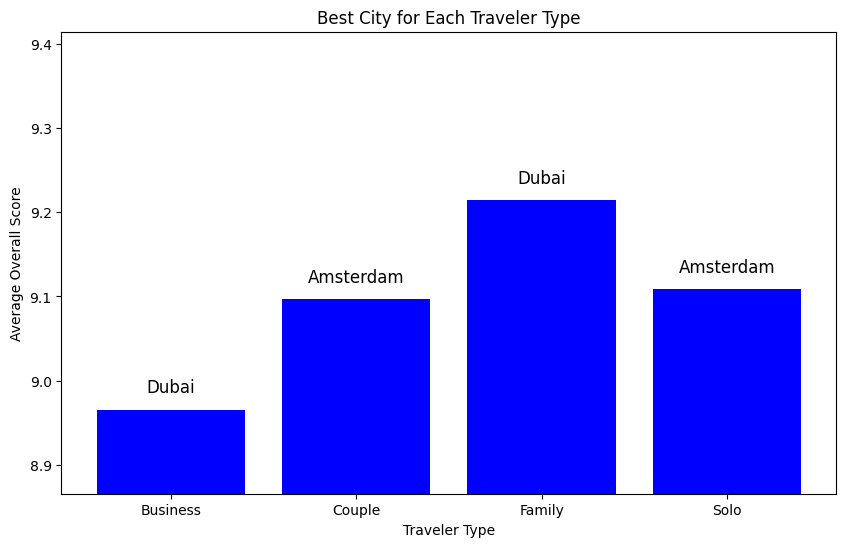

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate(zip(best_city_per_type['traveller_type'], 
                                                best_city_per_type['city'], 
                                                best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()

# [](http://)Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [15]:
print(merged_df['age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


In [16]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['age_group', 'country_y'])['score_value_for_money'].mean().reset_index()

In [17]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('age_group').head(3) 
top3

,age_group,country_y,score_value_for_money
5,18-24,Egypt,9.007317
19,18-24,Spain,8.768132
0,18-24,Argentina,8.689000
44,25-34,Spain,8.733259
43,25-34,South Korea,8.632800
37,25-34,Netherlands,8.542157
66,35-44,Singapore,8.795385
50,35-44,Argentina,8.696519
63,35-44,New Zealand,8.641079
94,45-54,Turkey,8.641778


In [18]:
#features 
import pandas as pd
import numpy as np

df = merged_df.copy()   

# Numeric safety: ensure review and base cols are numeric
num_cols = [
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
    'star_rating','cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base'
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# 1) per-dimension gap: review score minus hotel base
dims = {
    'cleanliness':'score_cleanliness',
    'comfort':'score_comfort',
    'facilities':'score_facilities',
    'location':'score_location',
    'staff':'score_staff',
    'value_for_money':'score_value_for_money'
}
for base_name, score_col in [('cleanliness_base','score_cleanliness'),
                             ('comfort_base','score_comfort'),
                             ('facilities_base','score_facilities'),
                             ('location_base','score_location'),
                             ('staff_base','score_staff'),
                             ('value_for_money_base','score_value_for_money')]:
    new_col = score_col + '_minus_' + base_name
    df[new_col] = df[score_col] - df[base_name]

# 2) overall gap: overall review vs mean of hotel base dimensions
base_mean_cols = ['cleanliness_base','comfort_base','facilities_base','location_base','staff_base','value_for_money_base']
df['hotel_base_mean'] = df[base_mean_cols].mean(axis=1)
df['overall_minus_hotel_base_mean'] = df['score_overall'] - df['hotel_base_mean']

# 3) relative value: value-for-money gap normalized by star_rating (avoid /0)
df['value_for_money_per_star'] = df['score_value_for_money'] / df['star_rating'].replace(0, np.nan)

# 4) simple aggregate review score (average of review dimensions)
review_dims = ['score_cleanliness','score_comfort','score_facilities','score_location','score_staff','score_value_for_money']
df['avg_review_dim'] = df[review_dims].mean(axis=1)

# 5) consistency measure: std of review dimensions (how consistent user scores are)
df['review_std'] = df[review_dims].std(axis=1)

# Quick fill / drop if necessary
df = df.fillna(0)   # or choose a different imputation strategy

# Inspect new features
df[[c for c in df.columns if '_minus_' in c] + ['overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std']].head()
#score_X_minus_base_Y — shows how the customer's rating differs from the hotel’s baseline for that dimension. If guests systematically rate a hotel much lower than its base, that signals a gap between perceived and expected quality.
#overall_minus_hotel_base_mean — global “surprise” signal: does the overall experience exceed or fall short of the hotel’s typical standard? Useful to capture general sentiment vs expectation.
#value_for_money_per_star — normalises perceived value by hotel category. A 4-star hotel with poor value-for-money is different from a 2-star with the same score.
#avg_review_dim — compact summary of review dimensions (an alternative to score_overall).
#review_std — measures whether the review is consistent; high std → reviewer gave very different scores across dimensions (maybe noisy or picky).

,score_cleanliness_minus_cleanliness_base,score_comfort_minus_comfort_base,score_facilities_minus_facilities_base,score_location_minus_location_base,score_staff_minus_staff_base,score_value_for_money_minus_value_for_money_base,overall_minus_hotel_base_mean,overall_minus_hotel_base_mean,value_for_money_per_star,avg_review_dim,review_std
0,-0.5,-0.1,-0.4,-0.5,0.2,0.7,-0.116667,-0.116667,1.74,8.716667,0.172240
1,0.4,0.1,-0.3,0.1,-0.1,0.4,0.083333,0.083333,1.72,9.116667,0.530723
2,0.9,0.1,-0.3,-0.4,-0.6,0.2,0.083333,0.083333,1.72,8.700000,0.554977
3,-0.2,-0.3,-0.4,-0.1,0.1,-0.5,-0.216667,-0.216667,1.66,8.883333,0.462241
4,-0.2,0.2,0.3,-0.7,0.3,0.3,0.083333,0.083333,1.78,9.050000,0.446094


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


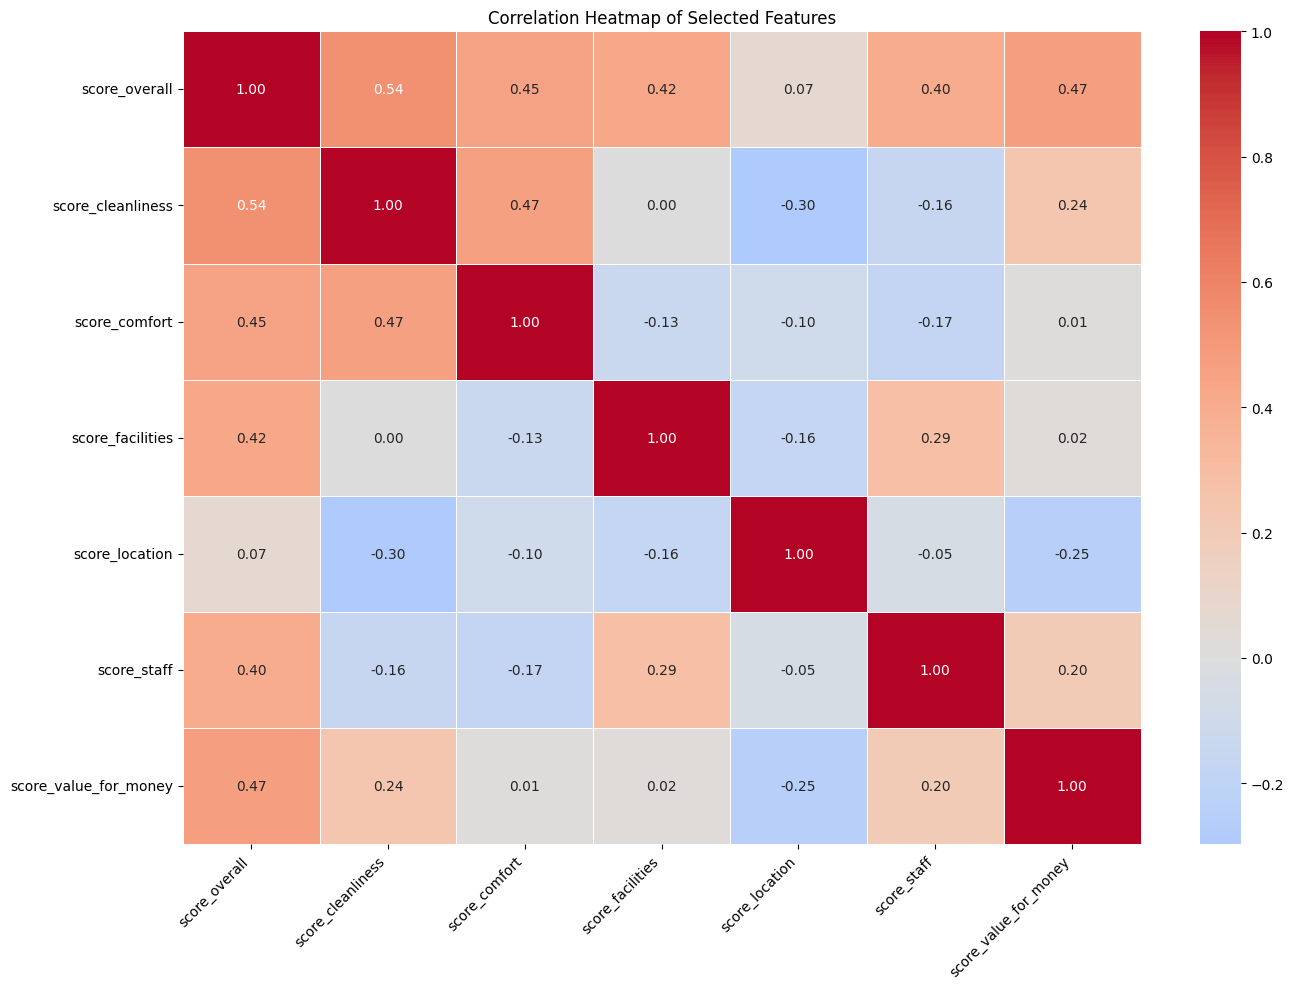

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    # raw review scores
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


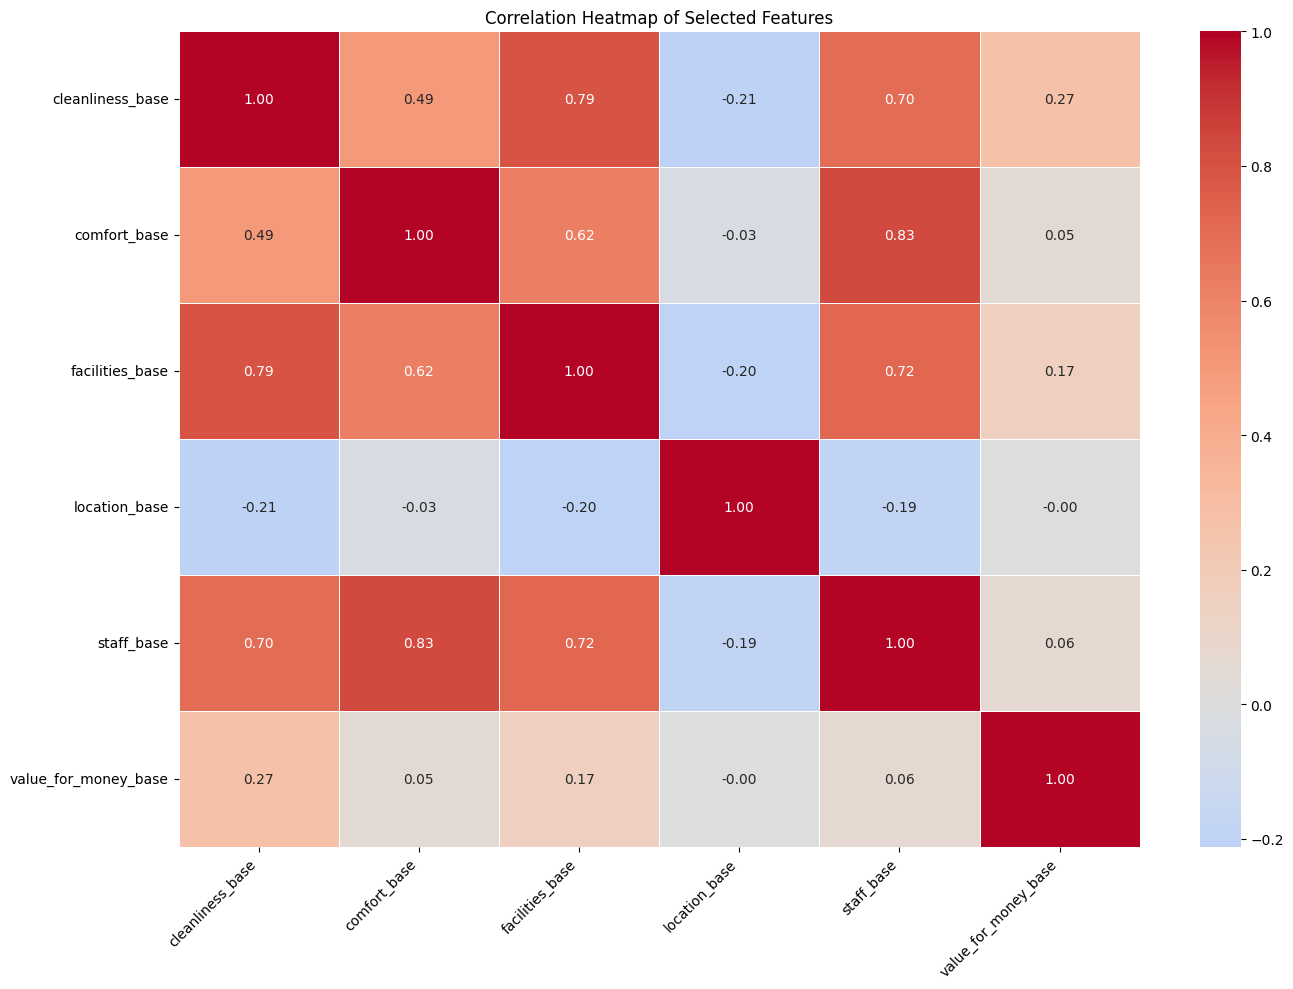

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    
    # hotel base
    'cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base',
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


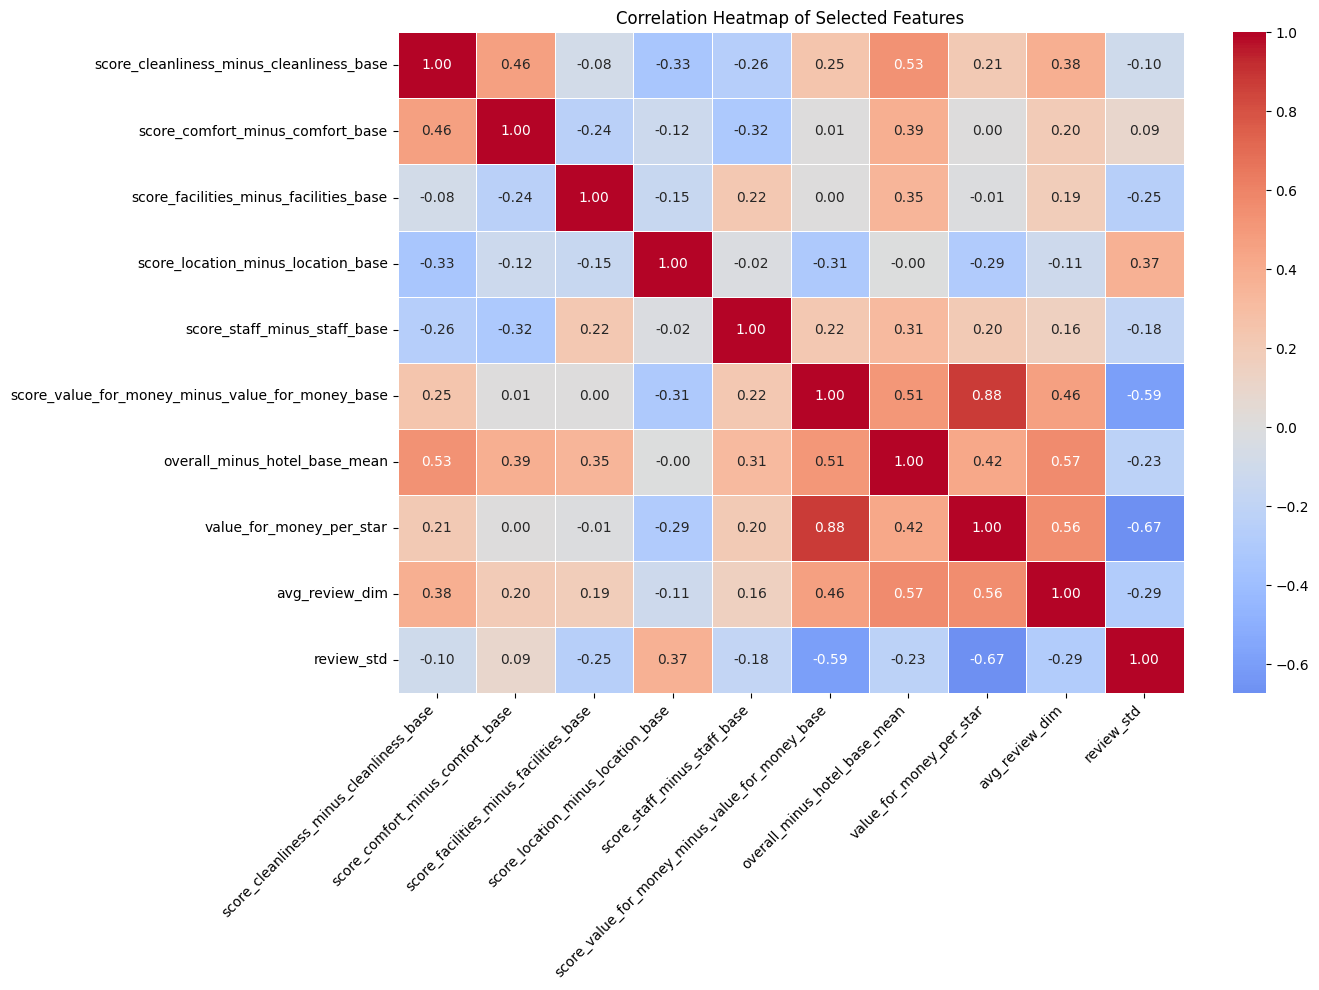

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    
    # derived quality features
    'score_cleanliness_minus_cleanliness_base','score_comfort_minus_comfort_base',
    'score_facilities_minus_facilities_base','score_location_minus_location_base',
    'score_staff_minus_staff_base','score_value_for_money_minus_value_for_money_base',
    'overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std',
    # user features (numerical or encoded)
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


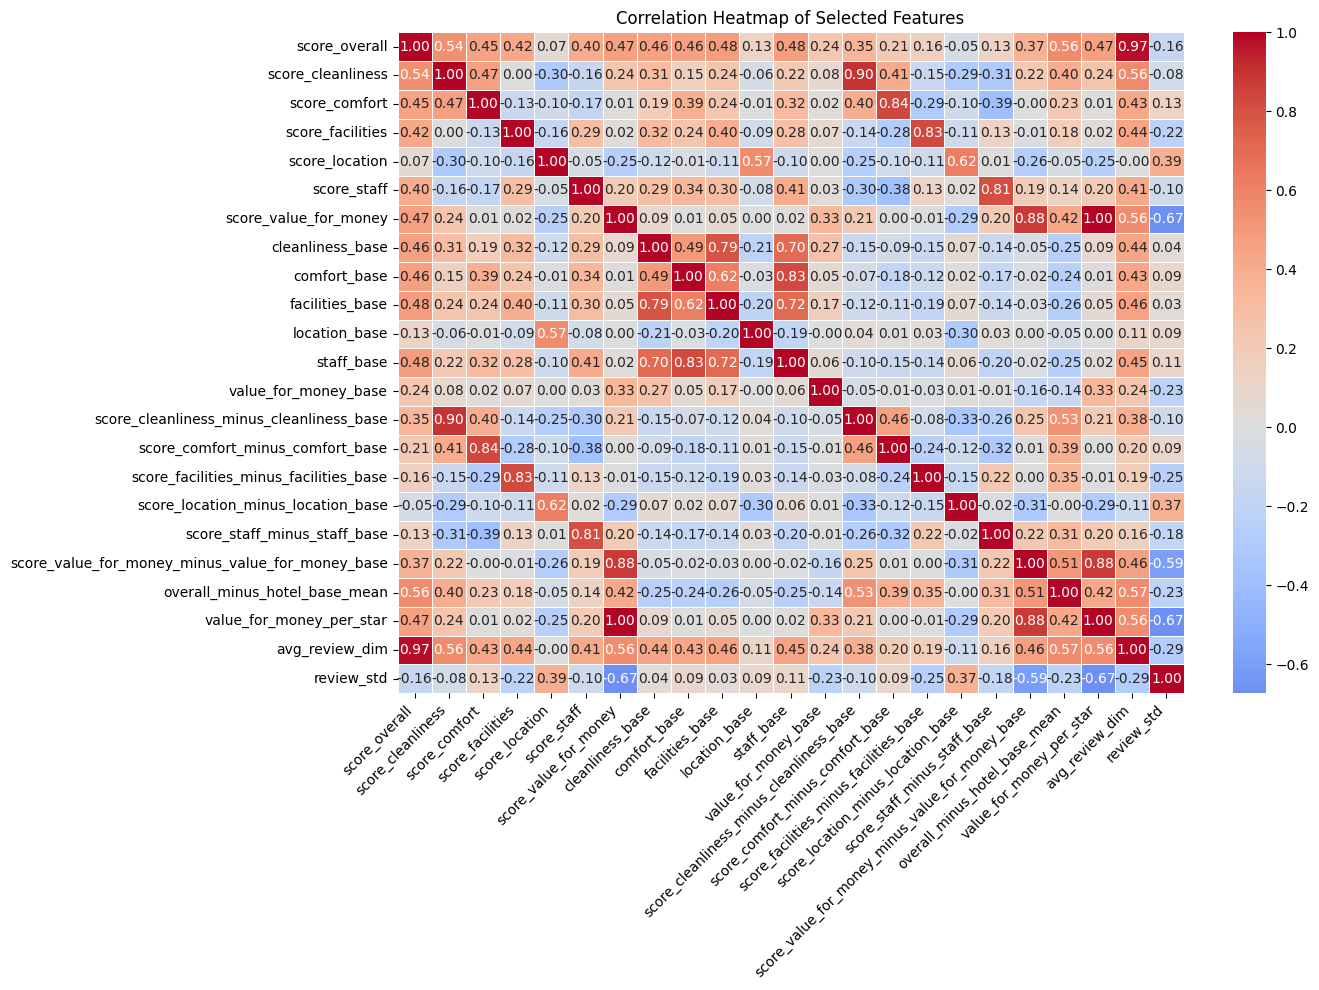

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose the features you want to inspect for correlation
feature_list = [
    # raw review scores
    'score_overall','score_cleanliness','score_comfort','score_facilities',
    'score_location','score_staff','score_value_for_money',
    # hotel base
    'cleanliness_base','comfort_base','facilities_base',
    'location_base','staff_base','value_for_money_base',
    # derived quality features
    'score_cleanliness_minus_cleanliness_base','score_comfort_minus_comfort_base',
    'score_facilities_minus_facilities_base','score_location_minus_location_base',
    'score_staff_minus_staff_base','score_value_for_money_minus_value_for_money_base',
    'overall_minus_hotel_base_mean','value_for_money_per_star','avg_review_dim','review_std',
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list = [c for c in feature_list if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# target
df = df.copy()
df = df.dropna(subset=['country_group'])  
le_target = LabelEncoder()
y = le_target.fit_transform(df['country_group'])  # multi-class integers

# features: pick clean numeric + encode categorical
# numeric features (as from feature_list)
X_num = df[feature_list].copy()

# encode categorical user features
# traveller_type, user_gender, age_group -> one-hot
cat_cols = [c for c in ['traveller_type','user_gender','age_group'] if c in df.columns]
X_cat = pd.get_dummies(df[cat_cols], drop_first=True)

# final X
X = pd.concat([X_num.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)

# scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# train/test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

In [24]:
import pandas as pd
import numpy as np

def remove_highly_correlated_features(df, threshold=0.85):
    """
    Remove features that are highly correlated with others (above threshold).
    Keeps the first feature in each correlated pair.
    Returns a reduced DataFrame and a list of dropped features.
    """
    corr_matrix = df.corr().abs()
    
    # Create an upper triangle mask (to avoid double-checking pairs)
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Find columns where any correlation is greater than threshold
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    print(f" Features to drop (correlation > {threshold}): {to_drop}")
    print(f" Remaining features: {len(df.columns) - len(to_drop)} of {len(df.columns)} kept.")
    
    return df.drop(columns=to_drop, errors='ignore'), to_drop

# Example use on your merged/engineered dataset
numeric_features = df.select_dtypes(include=[np.number])  # choose numeric only
clean_df, dropped = remove_highly_correlated_features(numeric_features, threshold=0.85)

# Your final feature matrix for modeling
X_final = clean_df.copy()
print("Final feature set shape:", X_final.shape)

 Features to drop (correlation > 0.85): ['score_cleanliness_minus_cleanliness_base', 'score_value_for_money_minus_value_for_money_base', 'value_for_money_per_star', 'avg_review_dim']
 Remaining features: 26 of 30 kept.
Final feature set shape: (50000, 26)


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


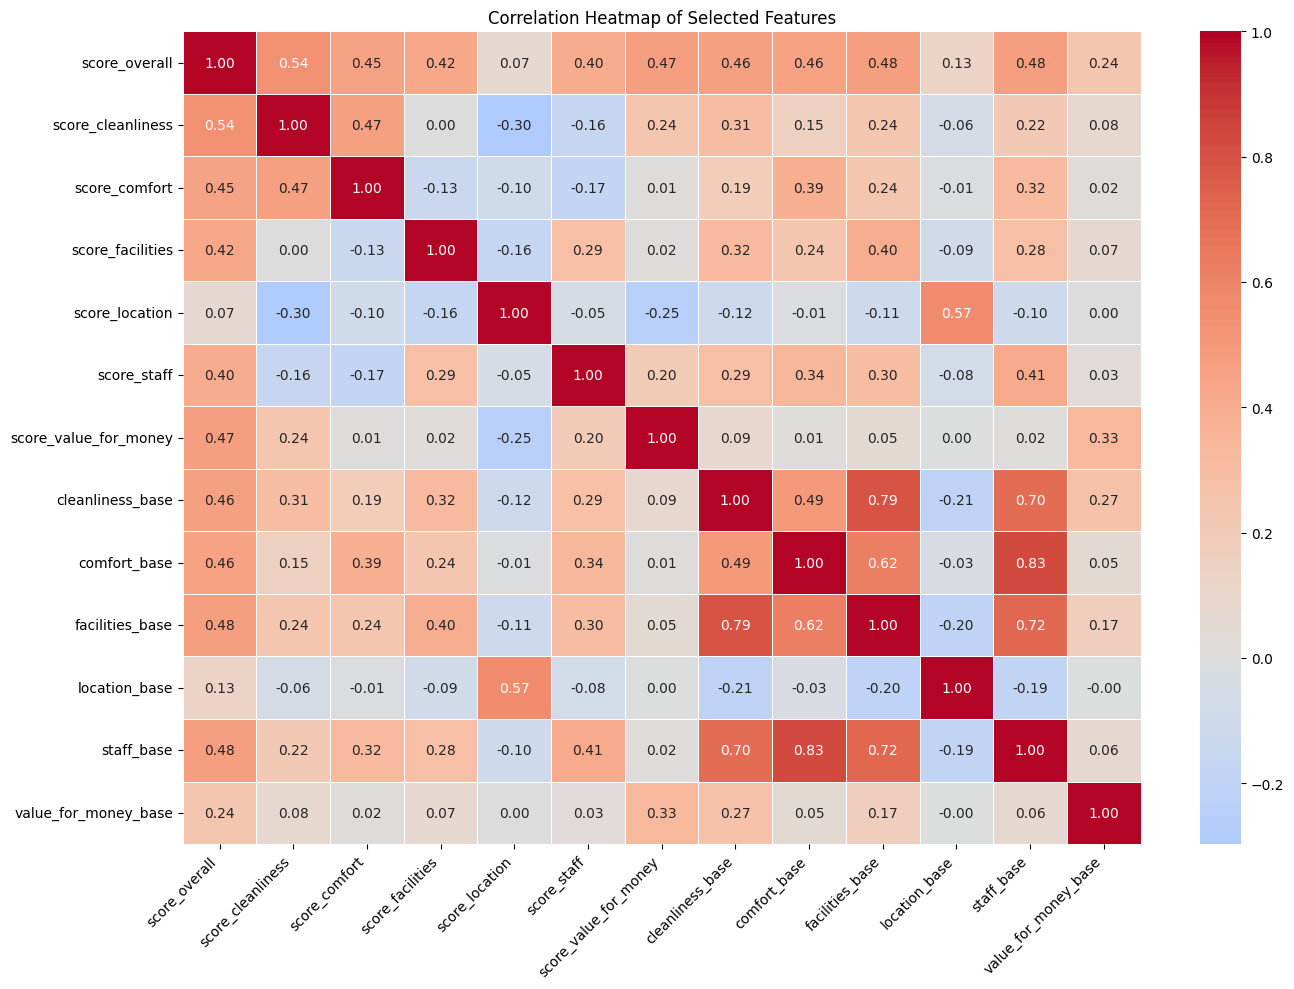

In [25]:
import seaborn as sns

#  the features you want to inspect for correlation
feature_list_Score_based = [
    'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities'
    , 'score_location', 'score_staff', 'score_value_for_money',
    'cleanliness_base', 'comfort_base', 'facilities_base', 'location_base', 
    'staff_base', 'value_for_money_base'

    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list_Score_based = [c for c in feature_list_Score_based if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list_Score_based].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


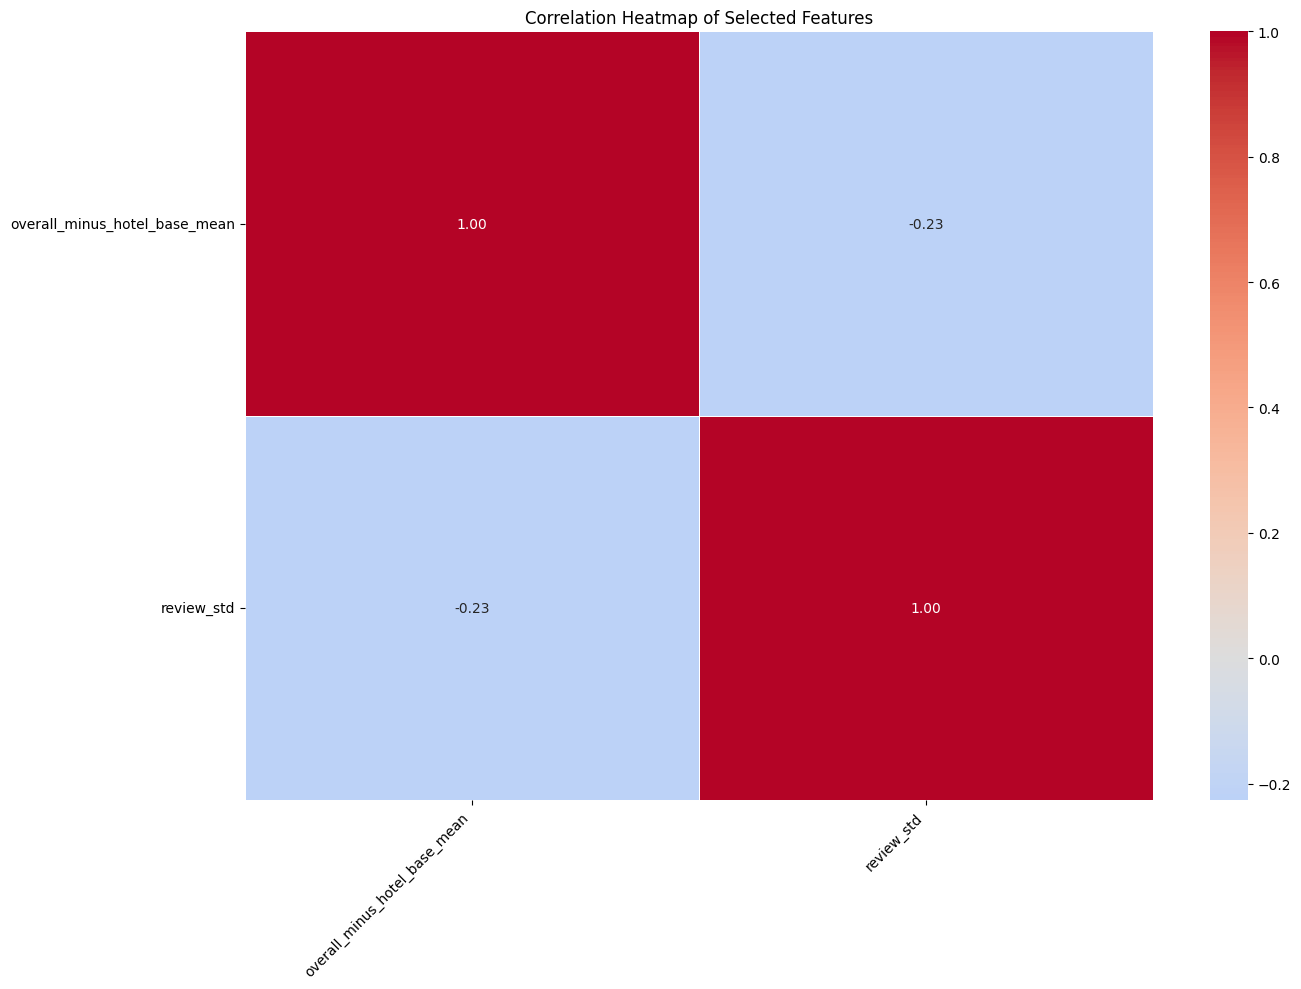

In [26]:
import seaborn as sns

#  the features you want to inspect for correlation
feature_list_Quality_based = [
    'overall_minus_hotel_base_mean', 'review_std'
    
]

# If your derived column names differ, adapt list to the columns actually in df:
# show which of those exist
feature_list_Quality_based = [c for c in feature_list_Quality_based if c in df.columns]

# compute correlation matrix
corr_df = df[feature_list_Quality_based].corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


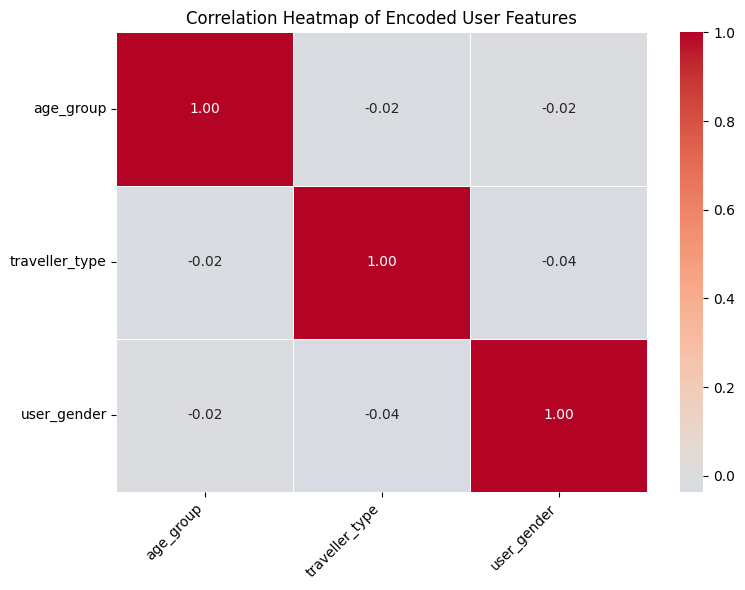

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# the features you want
feature_list_User_features = [
    'age_group', 'traveller_type', 'user_gender'
]

# keep only columns that exist
feature_list_User_features = [c for c in feature_list_User_features if c in df.columns]

# make a copy of those columns
corr_data = df[feature_list_User_features].copy()

# label encode each categorical column
encoder = LabelEncoder()
for col in corr_data.columns:
    corr_data[col] = encoder.fit_transform(corr_data[col].astype(str))

# compute correlation matrix
corr_df = corr_data.corr()

# plot heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Encoded User Features")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# combine X_final with encoded categorical features
cat_cols = [   # raw review scores
        'age_group', 'traveller_type', 'user_gender'
]
   
X_cat = pd.get_dummies(df[cat_cols], drop_first=True)

X_full = pd.concat([X_final.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)

# target
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df['country_group'])

print("Final features:", X_full.shape[1])
print("Target classes:", len(le.classes_))

Final features: 35
Target classes: 11


In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

In [30]:
# Step 1: Import all needed libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Step 2: Train and evaluate
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Step 3: Show results
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

Random Forest Accuracy: 0.4256
                      precision    recall  f1-score   support

              Africa       0.50      0.02      0.03       300
           East_Asia       0.49      0.31      0.38      1617
      Eastern_Europe       0.75      0.06      0.10       267
         Middle_East       0.55      0.04      0.08       491
       North_America       0.46      0.33      0.38      1888
North_America_Mexico       0.78      0.06      0.11       241
             Oceania       0.65      0.11      0.18       578
       South_America       0.37      0.04      0.07       675
          South_Asia       0.80      0.14      0.23       327
      Southeast_Asia       0.67      0.04      0.08       248
      Western_Europe       0.40      0.87      0.55      3368

            accuracy                           0.43     10000
           macro avg       0.58      0.18      0.20     10000
        weighted avg       0.49      0.43      0.35     10000



In [31]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective='multi:softmax', 
    num_class=len(le.classes_), 
    eval_metric='mlogloss', 
    random_state=42
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_))

XGBoost Accuracy: 0.8316
                      precision    recall  f1-score   support

              Africa       0.86      0.73      0.79       300
           East_Asia       0.86      0.74      0.80      1617
      Eastern_Europe       0.87      0.83      0.85       267
         Middle_East       0.89      0.72      0.79       491
       North_America       0.84      0.81      0.83      1888
North_America_Mexico       0.94      0.95      0.95       241
             Oceania       0.96      0.75      0.84       578
       South_America       0.89      0.72      0.80       675
          South_Asia       0.91      0.87      0.89       327
      Southeast_Asia       0.93      0.90      0.91       248
      Western_Europe       0.77      0.93      0.84      3368

            accuracy                           0.83     10000
           macro avg       0.88      0.81      0.84     10000
        weighted avg       0.84      0.83      0.83     10000



In [32]:
from tensorflow.keras import Sequential, Input, layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import SparseCategoricalAccuracy

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(len(le.classes_), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=[SparseCategoricalAccuracy(name='accuracy')]
)

early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

# evaluate
probs = model.predict(X_test)
y_pred_nn = probs.argmax(axis=1)

print("FFNN Accuracy:", accuracy_score(y_test, y_pred_nn))
print(classification_report(y_test, y_pred_nn, target_names=le.classes_))

2025-10-21 12:56:03.141744: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761051363.381947      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761051363.447802      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Epoch 1/100


2025-10-21 12:56:18.415494: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3170 - loss: 2.0323 - val_accuracy: 0.3340 - val_loss: 1.9477
Epoch 2/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3336 - loss: 1.9417 - val_accuracy: 0.3354 - val_loss: 1.9326
Epoch 3/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3441 - loss: 1.9038 - val_accuracy: 0.3467 - val_loss: 1.9065
Epoch 4/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3476 - loss: 1.8782 - val_accuracy: 0.3485 - val_loss: 1.8767
Epoch 5/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3511 - loss: 1.8488 - val_accuracy: 0.3549 - val_loss: 1.8542
Epoch 6/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3599 - loss: 1.8208 - val_accuracy: 0.3582 - val_loss: 1.8264
Epoch 7/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3633 - loss: 1.7933 - val_accuracy: 0.3620 - val_loss: 1.8062
Epoch 8/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3704 - loss: 1.7740 - val_

In [33]:
import shap
import pandas as pd
shap.initjs()


In [34]:
explainer = shap.TreeExplainer(xgb)